# NFL Fantasy Football Trade Analyzer

### Python | Pandas | NumPy | Scikit-learn | Plotly | Matplotlib | Seaborn

This project develops a data-driven fantasy football analytics and trade evaluation system using multi-season NFL player statistics.

The workflow combines exploratory data analysis, historical feature engineering, machine learning, player projections, position-relative valuation, and an interactive trade analyzer. The analyzer evaluates how a proposed trade may affect a team's optimized starting lineup under configurable roster settings.

The project uses **PPR scoring** throughout.

## 1. Project Objective

The objective of this project is to build a reproducible Python analytics workflow that turns NFL player statistics into useful fantasy football insights and trade evaluations.

The project is designed to:

- Analyze player production, usage, efficiency, and scoring consistency.
- Engineer historical performance features without using future information.
- Train and evaluate machine learning models to estimate a player's PPR points in their next recorded appearance.
- Combine projected production, historical performance, and consistency into a position-relative player valuation score.
- Compare multi-player trades and evaluate their impact on an optimized starting lineup.
- Account for league lineup requirements, bench depth, and user-selected roster needs.

The analyzer is a decision-support tool. Its projections and trade recommendations are estimates, not guarantees of future performance.

## 2. Data Collection and Preparation

This section retrieves NFLverse weekly player statistics, filters the data to regular-season fantasy-relevant positions, and checks the resulting dataset for data-quality issues.

In [1]:
# Install the NFLverse data package
!pip install -q nflreadpy

# Data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Machine learning
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# NFL data
import nflreadpy as nfl

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Consistent chart formatting
sns.set_theme(style="whitegrid")

### Data Sources

This project uses NFL data from **NFLverse**, an open-source collection of NFL datasets.

The primary source is weekly player statistics, which include:

- Player identifiers, names, positions, teams, and opponents.
- Passing, rushing, and receiving statistics.
- Fantasy scoring and PPR fantasy points.
- Available usage and efficiency metrics.

The notebook retrieves the five most recent NFL seasons available when it is run, using `nflreadpy`. The exact seasons and record counts are displayed by the data-loading and assessment cells.

NFLverse project: https://github.com/nflverse

In [2]:
# Find the current NFL season and week
current_season = nfl.get_current_season()
current_week = nfl.get_current_week()

# Load Weekly Player Statistics
weekly_stats = nfl.load_player_stats(
    seasons=range(current_season - 4, current_season + 1)
)

# Convert to a Pandas DataFrame
weekly_stats = weekly_stats.to_pandas()

# Display the first five rows
weekly_stats.head()

,player_id,player_name,player_display_name,position,position_group,headshot_url,season,week,season_type,game_id,...,pt_out_of_bounds,pt_downed,pt_touchback,pt_fair_caught,pt_returned,pt_return_yards,pt_return_tds,pt_net_yards,fantasy_points,fantasy_points_ppr
0,00-0019596,T.Brady,Tom Brady,QB,QB,https://static.www.nfl.com/image/private/f_aut...,2022,1,REG,2022_01_TB_DAL,...,0,0,0,0,0,0,0,0,10.38,10.38
1,00-0022824,A.Lee,Andy Lee,P,SPEC,https://static.www.nfl.com/image/private/f_aut...,2022,1,REG,2022_01_KC_ARI,...,0,0,0,0,5,44,0,211,0.00,0.00
2,00-0023252,R.Gould,Robbie Gould,K,SPEC,https://static.www.nfl.com/image/private/f_aut...,2022,1,REG,2022_01_SF_CHI,...,0,0,0,0,0,0,0,0,0.00,0.00
3,00-0023459,A.Rodgers,Aaron Rodgers,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2022,1,REG,2022_01_GB_MIN,...,0,0,0,0,0,0,0,0,3.70,3.70
4,00-0023853,M.Prater,Matt Prater,K,SPEC,https://static.www.nfl.com/image/upload/f_auto...,2022,1,REG,2022_01_KC_ARI,...,0,0,0,0,0,0,0,0,0.00,0.00


In [3]:
# Display the size of the dataset
print("Dataset shape:", weekly_stats.shape)

# Display column names
print("\nColumn names:")
print(weekly_stats.columns.tolist())

# Display data types and non-null values
print("\nDataset information")
weekly_stats.info()

Dataset shape: (87004, 150)

Column names:
['player_id', 'player_name', 'player_display_name', 'position', 'position_group', 'headshot_url', 'season', 'week', 'season_type', 'game_id', 'team', 'opponent_team', 'completions', 'attempts', 'passing_yards', 'passing_tds', 'passing_interceptions', 'sacks_suffered', 'sack_yards_lost', 'sack_fumbles', 'sack_fumbles_lost', 'passing_air_yards', 'passing_yards_after_catch', 'passing_first_downs', 'passing_epa', 'passing_cpoe', 'passing_2pt_conversions', 'pacr', 'passing_10', 'passing_16', 'passing_20', 'passing_40', 'carries', 'rushing_yards', 'rushing_tds', 'rushing_fumbles', 'rushing_fumbles_lost', 'rushing_first_downs', 'rushing_epa', 'rushing_2pt_conversions', 'rushing_10', 'rushing_12', 'rushing_20', 'rushing_40', 'receptions', 'targets', 'receiving_yards', 'receiving_tds', 'receiving_fumbles', 'receiving_fumbles_lost', 'receiving_air_yards', 'receiving_yards_after_catch', 'receiving_first_downs', 'receiving_epa', 'receiving_2pt_conversions

### Initial Data Assessment

The raw weekly player statistics dataset contains multiple NFL seasons and a wide range of player-performance variables.

The assessment below checks:

- Dataset dimensions and available columns.
- Seasons and positions represented.
- Missing values in player-identification fields.
- Duplicate player-game and player-week records.

Record counts are generated dynamically because the NFLverse dataset changes as new games and seasons become available.

In [4]:
# Check the positions represented in the dataset
weekly_stats["position"].value_counts()

,count
position,
LB,12133
WR,11788
CB,9297
RB,7362
DT,7260
DE,7052
TE,5933
SAF,5799
QB,3115


In [5]:

# Define the fantasy-relevant positions
fantasy_positions = ["QB", "RB", "WR", "TE"]

# Keep regular-season games and fantasy-relevant positions
fantasy_stats = weekly_stats[
    (weekly_stats["season_type"] == "REG") &
    (weekly_stats["position"].isin(fantasy_positions))
].copy()

# Sort the data chronologically
fantasy_stats = fantasy_stats.sort_values(
    ["season", "week", "player_id"]
).reset_index(drop=True)

# Check the resulting dataset
print("Fantasy dataset shape:", fantasy_stats.shape)

print("\nSeasons included:")
print(sorted(fantasy_stats["season"].unique()))

print("\nPositions included:")
print(fantasy_stats["position"].value_counts())

fantasy_stats.head()


Fantasy dataset shape: (27092, 150)

Seasons included:
[np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025), np.int32(2026)]

Positions included:
position
WR    11302
RB     7077
TE     5715
QB     2998
Name: count, dtype: int64


,player_id,player_name,player_display_name,position,position_group,headshot_url,season,week,season_type,game_id,...,pt_out_of_bounds,pt_downed,pt_touchback,pt_fair_caught,pt_returned,pt_return_yards,pt_return_tds,pt_net_yards,fantasy_points,fantasy_points_ppr
0,00-0019596,T.Brady,Tom Brady,QB,QB,https://static.www.nfl.com/image/private/f_aut...,2022,1,REG,2022_01_TB_DAL,...,0,0,0,0,0,0,0,0,10.38,10.38
1,00-0023459,A.Rodgers,Aaron Rodgers,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2022,1,REG,2022_01_GB_MIN,...,0,0,0,0,0,0,0,0,3.70,3.70
2,00-0026143,M.Ryan,Matt Ryan,QB,QB,https://static.www.nfl.com/image/private/f_aut...,2022,1,REG,2022_01_IND_HOU,...,0,0,0,0,0,0,0,0,15.28,15.28
3,00-0026158,J.Flacco,Joe Flacco,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2022,1,REG,2022_01_BAL_NYJ,...,0,0,0,0,0,0,0,0,14.36,14.36
4,00-0026197,C.Henne,Chad Henne,QB,QB,https://static.www.nfl.com/image/private/f_aut...,2022,1,REG,2022_01_KC_ARI,...,0,0,0,0,0,0,0,0,0.00,0.00


In [6]:

# Select the columns we need for analysis and modeling

# Core columns: player identity, game information, and fantasy production
core_cols = [
    "player_id",
    "player_name",
    "player_display_name",
    "position",
    "position_group",
    "season",
    "week",
    "season_type",
    "game_id",
    "team",
    "opponent_team",

    # Passing
    "passing_yards",
    "passing_tds",
    "passing_interceptions",
    "passing_epa",
    "passing_cpoe",

    # Rushing
    "carries",
    "rushing_yards",
    "rushing_tds",
    "rushing_epa",

    # Receiving
    "receptions",
    "targets",
    "receiving_yards",
    "receiving_tds",
    "receiving_epa",
    "target_share",
    "air_yards_share",

    # Fantasy production
    "fantasy_points",
    "fantasy_points_ppr"
]

# Additional usage and performance metrics
optional_cols = [
    "attempts",
    "passing_air_yards",
    "passing_first_downs",
    "rushing_first_downs",
    "receiving_first_downs",
    "receiving_fumbles_lost",
    "rushing_fumbles_lost",
    "offense_snaps",
    "offense_pct",
    "team_snaps",
    "racr",
    "wopr",
    "adot",
    "pacr"
]

# Check which columns are available in the dataset
available_core = [
    col for col in core_cols if col in fantasy_stats.columns
]

missing_core = [
    col for col in core_cols if col not in fantasy_stats.columns
]

available_optional = [
    col for col in optional_cols if col in fantasy_stats.columns
]

# Keep all available core and optional columns
fantasy_cols = available_core + available_optional

fantasy_stats = fantasy_stats[fantasy_cols].copy()

# Display dataset information
print("Selected dataset shape:", fantasy_stats.shape)

print("\nAdditional metrics included:")
print(available_optional)

print("\nCore columns not available:")
print(missing_core)

print("\nFinal columns:")
print(fantasy_stats.columns.tolist())

fantasy_stats.head()



Selected dataset shape: (27092, 39)

Additional metrics included:
['attempts', 'passing_air_yards', 'passing_first_downs', 'rushing_first_downs', 'receiving_first_downs', 'receiving_fumbles_lost', 'rushing_fumbles_lost', 'racr', 'wopr', 'pacr']

Core columns not available:
[]

Final columns:
['player_id', 'player_name', 'player_display_name', 'position', 'position_group', 'season', 'week', 'season_type', 'game_id', 'team', 'opponent_team', 'passing_yards', 'passing_tds', 'passing_interceptions', 'passing_epa', 'passing_cpoe', 'carries', 'rushing_yards', 'rushing_tds', 'rushing_epa', 'receptions', 'targets', 'receiving_yards', 'receiving_tds', 'receiving_epa', 'target_share', 'air_yards_share', 'fantasy_points', 'fantasy_points_ppr', 'attempts', 'passing_air_yards', 'passing_first_downs', 'rushing_first_downs', 'receiving_first_downs', 'receiving_fumbles_lost', 'rushing_fumbles_lost', 'racr', 'wopr', 'pacr']


,player_id,player_name,player_display_name,position,position_group,season,week,season_type,game_id,team,...,attempts,passing_air_yards,passing_first_downs,rushing_first_downs,receiving_first_downs,receiving_fumbles_lost,rushing_fumbles_lost,racr,wopr,pacr
0,00-0019596,T.Brady,Tom Brady,QB,QB,2022,1,REG,2022_01_TB_DAL,TB,...,27,305,9,0,0,0,0,NaN,0.0,0.695082
1,00-0023459,A.Rodgers,Aaron Rodgers,QB,QB,2022,1,REG,2022_01_GB_MIN,GB,...,34,190,9,0,0,0,0,NaN,0.0,1.026316
2,00-0026143,M.Ryan,Matt Ryan,QB,QB,2022,1,REG,2022_01_IND_HOU,IND,...,50,313,20,2,0,0,1,NaN,0.0,1.124601
3,00-0026158,J.Flacco,Joe Flacco,QB,QB,2022,1,REG,2022_01_BAL_NYJ,NYJ,...,59,286,18,0,0,0,0,NaN,0.0,1.080420
4,00-0026197,C.Henne,Chad Henne,QB,QB,2022,1,REG,2022_01_KC_ARI,KC,...,0,0,0,0,0,0,0,NaN,0.0,NaN


In [7]:
# Check for duplicate player-game records
print("Total records:", len(fantasy_stats))

duplicate_rows = fantasy_stats.duplicated(
    subset=["player_id", "season", "game_id"],
    keep=False
)

print("Duplicate player-game records:", duplicate_rows.sum())

# Display duplicate records if any exist
duplicates = fantasy_stats[duplicate_rows].sort_values(
    ["player_id", "season", "game_id"]
)

duplicates.head(20)


Total records: 27092
Duplicate player-game records: 0


,player_id,player_name,player_display_name,position,position_group,season,week,season_type,game_id,team,...,attempts,passing_air_yards,passing_first_downs,rushing_first_downs,receiving_first_downs,receiving_fumbles_lost,rushing_fumbles_lost,racr,wopr,pacr


In [8]:
# Check for missing values in each column
missing_values = fantasy_stats.isnull().sum()

# Display only columns that contain missing values
missing_values[missing_values > 0].sort_values(ascending=False)

,0
passing_cpoe,24125
pacr,24115
passing_epa,24069
rushing_epa,16893
racr,7614
receiving_epa,7493


In [9]:
#Check for missing values in important player identification columns
player_info_cols = [
    "player_id",
    "player_name",
    "player_display_name",
    "position",
    "team"
]

fantasy_stats[player_info_cols].isnull().sum()

,0
player_id,0
player_name,0
player_display_name,0
position,0
team,0


In [10]:
# Review missing values in advanced metrics.
# Missing advanced metrics are preserved rather than automatically replaced with zero.
# A missing value can mean that a metric was not recorded or is not applicable.

advanced_metric_cols = [
    col for col in [
        "passing_cpoe",
        "passing_epa",
        "rushing_epa",
        "receiving_epa",
        "racr",
        "pacr"
    ]
    if col in fantasy_stats.columns
]

fantasy_stats[advanced_metric_cols].isnull().sum().sort_values(
    ascending=False
)

,0
passing_cpoe,24125
pacr,24115
passing_epa,24069
rushing_epa,16893
racr,7614
receiving_epa,7493


In [11]:
# Check for duplicate player-week records
duplicate_records = fantasy_stats.duplicated(
    subset=["player_id", "season", "week"],
    keep=False
)

print("Duplicate player-week records:", duplicate_records.sum())

# Display duplicates if any exist
fantasy_stats[duplicate_records].sort_values(
    ["player_id", "season", "week"]
).head(20)

Duplicate player-week records: 0


,player_id,player_name,player_display_name,position,position_group,season,week,season_type,game_id,team,...,attempts,passing_air_yards,passing_first_downs,rushing_first_downs,receiving_first_downs,receiving_fumbles_lost,rushing_fumbles_lost,racr,wopr,pacr


## 3. Exploratory Data Analysis (EDA)

This section explores NFL player performance, fantasy scoring trends, positional differences, player consistency, usage, and efficiency. The goal is to identify patterns that help explain fantasy production and inform the predictive modeling stage.

### 3.1 Average PPR by Position

In [12]:
position_analysis = (
    fantasy_stats
    .groupby("position")
    .agg(
        total_games=("fantasy_points_ppr", "count"),
        avg_ppr=("fantasy_points_ppr", "mean"),
        std_ppr=("fantasy_points_ppr", "median"),
        total_ppr=("fantasy_points_ppr", "sum")
    )
    .round(2)
    .sort_values("avg_ppr", ascending=False)
)
position_analysis

,total_games,avg_ppr,std_ppr,total_ppr
position,,,,
QB,2998,13.58,13.59,40699.16
RB,7077,7.71,5.30,54568.28
WR,11302,7.18,4.80,81202.28
TE,5715,5.45,3.40,31152.24


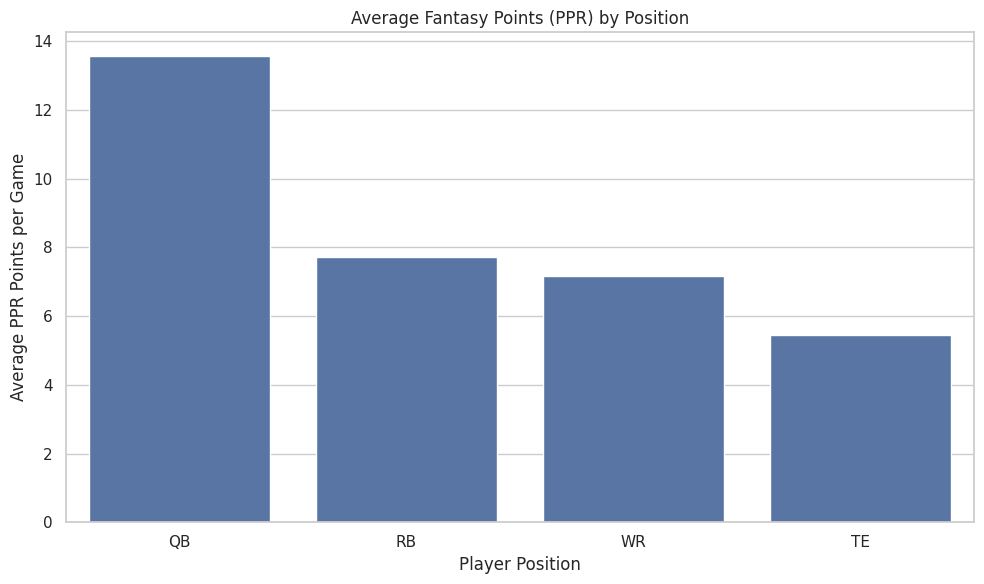

In [13]:
# Visualize average PPR points by position
plt.figure(figsize=(10, 6))

sns.barplot(
    data = position_analysis.reset_index(),
    x="position",
    y="avg_ppr"
)

plt.title("Average Fantasy Points (PPR) by Position")
plt.xlabel("Player Position")
plt.ylabel("Average PPR Points per Game")

plt.tight_layout()
plt.show()


## 3.2 Top 15 Players by Average PPR Points per Game

Identify the highest-performing players based on their average PPR production across recorded games.


In [14]:
# Calculate player-level fantasy performance

player_performance = (
    fantasy_stats
    .groupby(
        ["player_id", "player_display_name", "position"],
        as_index=False
    )
    .agg(
        games_played=("fantasy_points_ppr", "count"),
        avg_ppr=("fantasy_points_ppr", "mean"),
        total_ppr=("fantasy_points_ppr", "sum")
    )
)
# Filter players with at least 8 games played
player_performance = player_performance[
    player_performance["games_played"] >= 8
]

# Identify the top 15 players
top_15_players = (
    player_performance
    .sort_values("avg_ppr", ascending=False)
    .head(15)
    .round(2)
)

top_15_players

,player_id,player_display_name,position,games_played,avg_ppr,total_ppr
277,00-0034857,Josh Allen,QB,75,23.56,1767.00
143,00-0033280,Christian McCaffrey,RB,63,22.62,1425.06
793,00-0039139,Jahmyr Gibbs,RB,59,21.24,1253.10
446,00-0036389,Jalen Hurts,QB,68,21.04,1431.06
790,00-0039075,Puka Nacua,WR,51,20.66,1053.70
460,00-0036442,Joe Burrow,QB,60,20.62,1237.44
264,00-0034796,Lamar Jackson,QB,63,20.50,1291.62
519,00-0036900,Ja'Marr Chase,WR,70,20.22,1415.52
185,00-0033873,Patrick Mahomes,QB,73,20.12,1468.68
896,00-0039910,Jayden Daniels,QB,31,19.55,606.06



## 3.3 Top 15 Fantasy Players Visualization


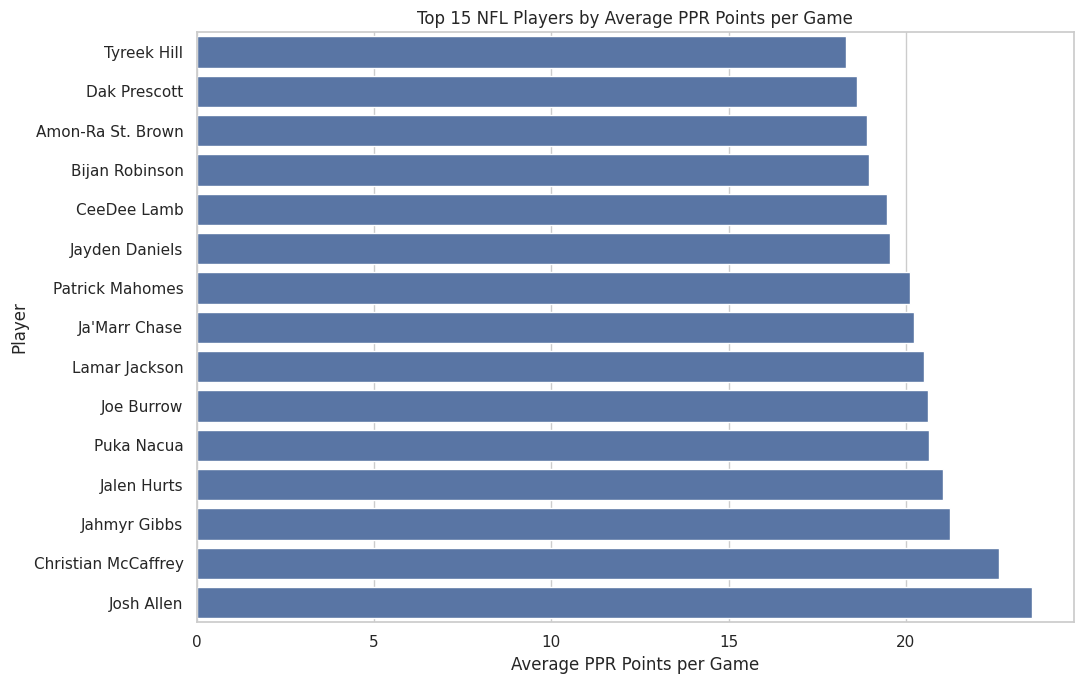

In [15]:
# Visualize the top 15 players by average PPR
plt.figure(figsize=(11, 7))

sns.barplot(
    data=top_15_players.sort_values("avg_ppr", ascending=True),
    x="avg_ppr",
    y="player_display_name"
)

plt.title("Top 15 NFL Players by Average PPR Points per Game")
plt.xlabel("Average PPR Points per Game")
plt.ylabel("Player")

plt.tight_layout()
plt.show()


## 3.4 Player Consistency Analysis

Evaluate player consistency using the standard deviation of weekly PPR points. Lower standard deviation indicates more consistent fantasy production, while higher standard deviation indicates greater variation in weekly scoring.


In [16]:

# Calculate player consistency

player_consistency = (
    fantasy_stats
    .groupby(
        ["player_id", "player_display_name", "position"],
        as_index=False
    )
    .agg(
        games_played=("fantasy_points_ppr", "count"),
        avg_ppr=("fantasy_points_ppr", "mean"),
        std_ppr=("fantasy_points_ppr", "std"),
        median_ppr=("fantasy_points_ppr", "median")
    )
)

# Focus on players with meaningful fantasy production
player_consistency = player_consistency[
    (player_consistency["games_played"] >= 8) &
    (player_consistency["avg_ppr"] >= 8)
]

# Rank by lowest scoring variation
player_consistency = player_consistency.sort_values(
    "std_ppr",
    ascending=True
).round(2)

player_consistency.head(15)


,player_id,player_display_name,position,games_played,avg_ppr,std_ppr,median_ppr
1043,00-0041040,Antonio Williams,WR,9,8.07,4.17,6.10
359,00-0035664,Darrell Henderson,RB,14,8.36,4.27,8.60
919,00-0040128,Tyler Warren,TE,26,10.70,5.23,9.40
44,00-0030513,Latavius Murray,RB,28,8.47,5.37,7.65
822,00-0039376,Spencer Rattler,QB,16,10.40,5.42,11.27
727,00-0038621,DeMario Douglas,WR,56,8.01,5.48,6.35
127,00-0033009,Tyler Boyd,WR,48,8.13,5.54,6.45
517,00-0036894,Pat Freiermuth,TE,68,8.95,5.59,7.45
985,00-0040583,Woody Marks,RB,25,8.94,5.61,8.20
776,00-0038997,Josh Downs,WR,58,9.99,5.62,9.00



## 3.5 Player Consistency vs. Fantasy Production


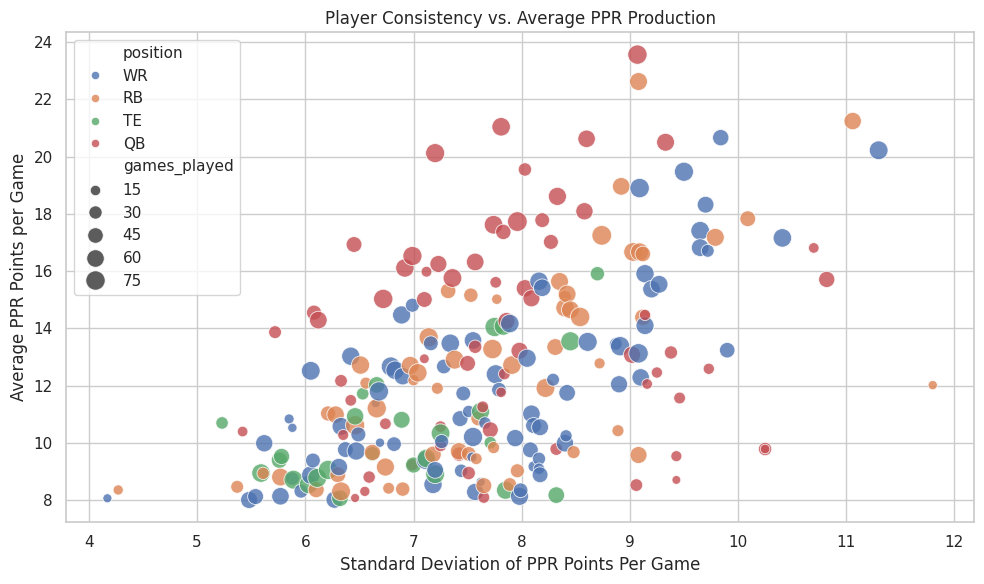

In [17]:
# Compare average PPR production and scoring consistency
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=player_consistency,
    x="std_ppr",
    y="avg_ppr",
    hue="position",
    size="games_played",
    sizes=(40,200),
    alpha=0.8
)

plt.title("Player Consistency vs. Average PPR Production")
plt.xlabel("Standard Deviation of PPR Points Per Game")
plt.ylabel("Average PPR Points per Game")

plt.tight_layout()
plt.show()


## 3.6 Player Usage vs. Fantasy Production

Analyze the relationship between player opportunities, including targets and carries, and average PPR production.


In [18]:
usage_analysis = (
    fantasy_stats
    .groupby(
        ["player_id", "player_display_name", "position"],
        as_index=False
    )
    .agg(
        games_played=("fantasy_points_ppr", "count"),
        avg_ppr=("fantasy_points_ppr", "mean"),
        targets_per_game=("targets", "mean"),
        carries_per_game=("carries", "mean")
    )
)

# Focus on players with at least 8 games
usage_analysis = usage_analysis[
    usage_analysis["games_played"] >=8
]

usage_analysis.head()

,player_id,player_display_name,position,games_played,avg_ppr,targets_per_game,carries_per_game
0,00-0019596,Tom Brady,QB,17,15.980000,0.058824,1.705882
2,00-0023459,Aaron Rodgers,QB,61,14.288525,0.016393,1.573770
3,00-0024243,Marcedes Lewis,TE,18,2.261111,0.722222,0.000000
4,00-0026143,Matt Ryan,QB,12,12.940000,0.000000,2.250000
5,00-0026158,Joe Flacco,QB,30,13.162667,0.000000,1.400000


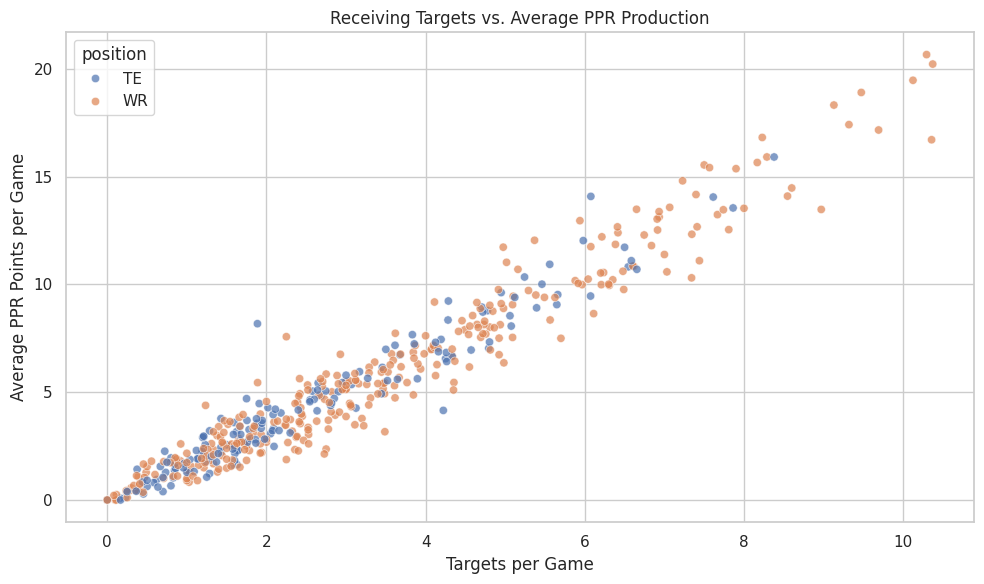

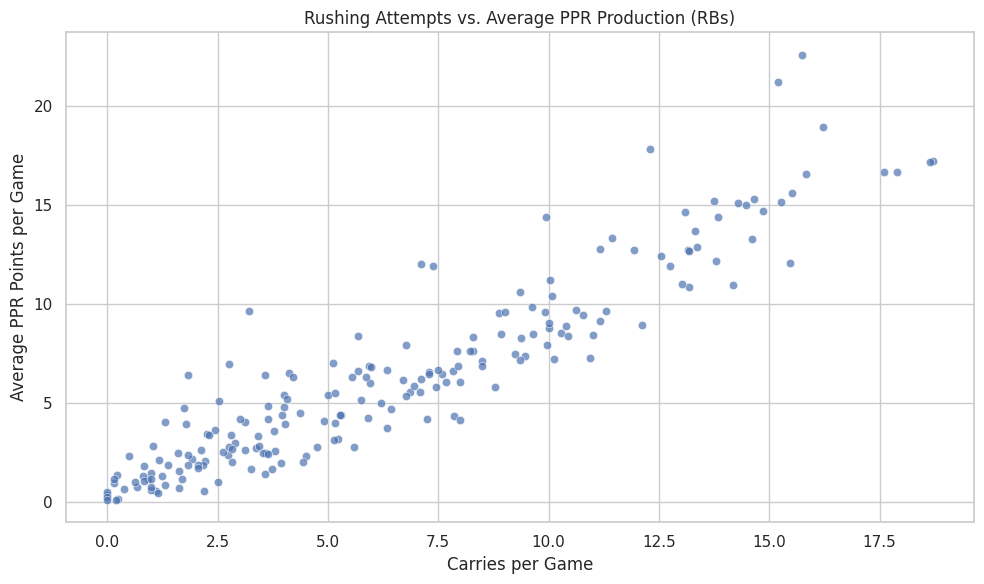

In [19]:
receiving_usage = usage_analysis[
    usage_analysis["position"].isin(["WR", "TE"])
]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=receiving_usage,
    x="targets_per_game",
    y="avg_ppr",
    hue="position",
    alpha=0.7
)

plt.title("Receiving Targets vs. Average PPR Production")
plt.xlabel("Targets per Game")
plt.ylabel("Average PPR Points per Game")

plt.tight_layout()
plt.show()

# Compare rushing usage and fantasy production for RBs

rushing_usage = usage_analysis[
    usage_analysis["position"] == "RB"
]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rushing_usage,
    x="carries_per_game",
    y="avg_ppr",
    alpha=0.7
)

plt.title("Rushing Attempts vs. Average PPR Production (RBs)")
plt.xlabel("Carries per Game")
plt.ylabel("Average PPR Points per Game")

plt.tight_layout()
plt.show()


## 3.7 Correlation Between Player Usage and Fantasy Production


In [20]:
# Calculate usage and fantasy production correlations
wr_te_correlation = receiving_usage[
    ["targets_per_game", "avg_ppr"]
].corr().iloc[0, 1]

rb_correlation = rushing_usage[
    ["carries_per_game", "avg_ppr"]
].corr().iloc[0, 1]

print("Targets vs. Average PPR (WRs and TEs):",
      round(wr_te_correlation, 3))
print("Carries vs. Average PPR(RBs):",
      round(rb_correlation, 3))

Targets vs. Average PPR (WRs and TEs): 0.971
Carries vs. Average PPR(RBs): 0.928



## 3.8 Player Efficiency Analysis

Evaluate player fantasy production relative to their opportunities. This analysis uses targets and carries to calculate fantasy points per opportunity for running backs, wide receivers, and tight ends.


In [21]:


# Calculate player fantasy points per opportunity

player_efficiency = (
    fantasy_stats[
        fantasy_stats["position"].isin(["RB", "WR", "TE"])
    ]
    .groupby(
        ["player_id", "player_display_name", "position"],
        as_index=False
    )
    .agg(
        games_played=("fantasy_points_ppr", "count"),
        total_ppr=("fantasy_points_ppr", "sum"),
        total_targets=("targets", "sum"),
        total_carries=("carries", "sum")
    )
)

# Calculate total opportunities
player_efficiency["total_opportunities"] = (
    player_efficiency["total_targets"] +
    player_efficiency["total_carries"]
)

# Calculate fantasy points per opportunity
player_efficiency["ppr_per_opportunity"] = (
    player_efficiency["total_ppr"] /
    player_efficiency["total_opportunities"].replace(0, np.nan)
)

# Filter players with sufficient games and opportunities
player_efficiency = player_efficiency[
    (player_efficiency["games_played"] >= 8) &
    (player_efficiency["total_opportunities"] >= 50)
]

# Rank players by efficiency
player_efficiency = player_efficiency.sort_values(
    "ppr_per_opportunity",
    ascending=False
).round(2)

# Display the top 15 most efficient players
player_efficiency.head(15)



,player_id,player_display_name,position,games_played,total_ppr,total_targets,total_carries,total_opportunities,ppr_per_opportunity
108,00-0033288,George Kittle,TE,66,929.5,401,2,403,2.31
619,00-0038608,Kayshon Boutte,WR,42,324.8,152,0,152,2.14
577,00-0038124,Christian Watson,WR,57,686.7,306,16,322,2.13
249,00-0035249,Josh Oliver,TE,52,222.6,105,0,105,2.12
422,00-0036754,Brock Wright,TE,49,180.9,86,0,86,2.10
771,00-0039855,Jalen McMillan,WR,18,165.3,74,5,79,2.09
672,00-0038996,Tucker Kraft,TE,49,452.3,210,8,218,2.07
374,00-0036410,Tee Higgins,WR,62,963.6,465,0,465,2.07
489,00-0037240,Jameson Williams,WR,60,661.5,301,22,323,2.05
259,00-0035329,Donald Parham,TE,20,108.5,53,0,53,2.05


### EDA Findings

The exploratory analysis highlights several patterns in NFL fantasy performance:

- Average PPR production differs across quarterback, running back, wide receiver, and tight end positions.
- Total fantasy-point contributions vary by position because positions have different numbers of players and scoring profiles.
- Players differ in both average production and week-to-week scoring consistency.
- Receiving targets are an important workload indicator for wide receivers and tight ends.
- Carries are an important workload indicator for running backs.
- Fantasy points per opportunity provide an additional efficiency perspective, but should be interpreted alongside player workload and sample size.

The correlation values and player-level rankings are calculated from the dataset in the current notebook run. These relationships are descriptive and do not establish that workload alone causes higher fantasy production.

## 4. Feature Engineering

Historical player statistics are transformed into predictive features. All rolling features are shifted so that a player's current or future performance is not used to construct that player's historical inputs.

The prediction target is the player's **next recorded game appearance**, which may not be the next calendar week if the player has a bye or misses a game.

In [22]:
fantasy_stats = fantasy_stats.sort_values(
    ["player_id", "season", "week"]
).reset_index(drop=True)

# Check the dataset
print("Dataset shape:", fantasy_stats.shape)
print("Seasons included:", sorted(fantasy_stats["season"].unique()))
print("Number of players:", fantasy_stats["player_id"].nunique())

Dataset shape: (27092, 39)
Seasons included: [np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025), np.int32(2026)]
Number of players: 1099


In [23]:
# Calculate each player's PPR from their previous game
fantasy_stats["previous_game_ppr"] = (
    fantasy_stats.groupby(
        ["player_id", "season"]
    )["fantasy_points_ppr"].shift(1)
)

# Display selected columns to verify the results
fantasy_stats[
    [
        "player_display_name",
        "season",
        "week",
        "fantasy_points_ppr",
        "previous_game_ppr"
    ]
].head(15)

,player_display_name,season,week,fantasy_points_ppr,previous_game_ppr
0,Tom Brady,2022,1,10.38,NaN
1,Tom Brady,2022,2,9.40,10.38
2,Tom Brady,2022,3,14.74,9.40
3,Tom Brady,2022,4,25.40,14.74
4,Tom Brady,2022,5,19.74,25.40
5,Tom Brady,2022,6,13.72,19.74
6,Tom Brady,2022,7,11.70,13.72
7,Tom Brady,2022,8,17.10,11.70
8,Tom Brady,2022,9,15.20,17.10
9,Tom Brady,2022,10,16.02,15.20


In [24]:

# Calculate average PPR over the previous 3 games
fantasy_stats["avg_ppr_last_3"] = (
    fantasy_stats.groupby(
        ["player_id", "season"]
    )["fantasy_points_ppr"]
    .transform(
        lambda x: x.shift(1).rolling(
            window=3,
            min_periods=1
        ).mean()
    )
)

# Display results
fantasy_stats[
    [
        "player_display_name",
        "season",
        "week",
        "fantasy_points_ppr",
        "previous_game_ppr",
        "avg_ppr_last_3"
    ]
].head(15)


,player_display_name,season,week,fantasy_points_ppr,previous_game_ppr,avg_ppr_last_3
0,Tom Brady,2022,1,10.38,NaN,NaN
1,Tom Brady,2022,2,9.40,10.38,10.380000
2,Tom Brady,2022,3,14.74,9.40,9.890000
3,Tom Brady,2022,4,25.40,14.74,11.506667
4,Tom Brady,2022,5,19.74,25.40,16.513333
5,Tom Brady,2022,6,13.72,19.74,19.960000
6,Tom Brady,2022,7,11.70,13.72,19.620000
7,Tom Brady,2022,8,17.10,11.70,15.053333
8,Tom Brady,2022,9,15.20,17.10,14.173333
9,Tom Brady,2022,10,16.02,15.20,14.666667


In [25]:

# Calculate workload averages over the previous 3 games

fantasy_stats["avg_targets_last_3"] = (
    fantasy_stats.groupby(
        ["player_id", "season"]
    )["targets"]
    .transform(
        lambda x: x.shift(1).rolling(
            window=3,
            min_periods=1
        ).mean()
    )
)

fantasy_stats["avg_carries_last_3"] = (
    fantasy_stats.groupby(
        ["player_id", "season"]
    )["carries"]
    .transform(
        lambda x: x.shift(1).rolling(
            window=3,
            min_periods=1
        ).mean()
    )
)

# Display the new features
fantasy_stats[
    [
        "player_display_name",
        "season",
        "week",
        "targets",
        "avg_targets_last_3",
        "carries",
        "avg_carries_last_3"
    ]
].head(15)


,player_display_name,season,week,targets,avg_targets_last_3,carries,avg_carries_last_3
0,Tom Brady,2022,1,0,NaN,2,NaN
1,Tom Brady,2022,2,0,0.000000,3,2.000000
2,Tom Brady,2022,3,0,0.000000,1,2.500000
3,Tom Brady,2022,4,0,0.000000,0,2.000000
4,Tom Brady,2022,5,0,0.000000,3,1.333333
5,Tom Brady,2022,6,0,0.000000,1,1.333333
6,Tom Brady,2022,7,0,0.000000,1,1.333333
7,Tom Brady,2022,8,0,0.000000,1,1.666667
8,Tom Brady,2022,9,0,0.000000,0,1.000000
9,Tom Brady,2022,10,1,0.000000,6,0.666667


In [26]:
# Create the target variable: PPR in the next recorded game
fantasy_stats["next_game_ppr"] = (
    fantasy_stats.groupby(
        ["player_id", "season"]
    )["fantasy_points_ppr"].shift(-1)
)

# Display the features and prediction target
fantasy_stats[
    [
        "player_display_name",
        "season",
        "week",
        "fantasy_points_ppr",
        "previous_game_ppr",
        "avg_ppr_last_3",
        "next_game_ppr"
    ]
].head(15)

,player_display_name,season,week,fantasy_points_ppr,previous_game_ppr,avg_ppr_last_3,next_game_ppr
0,Tom Brady,2022,1,10.38,NaN,NaN,9.40
1,Tom Brady,2022,2,9.40,10.38,10.380000,14.74
2,Tom Brady,2022,3,14.74,9.40,9.890000,25.40
3,Tom Brady,2022,4,25.40,14.74,11.506667,19.74
4,Tom Brady,2022,5,19.74,25.40,16.513333,13.72
5,Tom Brady,2022,6,13.72,19.74,19.960000,11.70
6,Tom Brady,2022,7,11.70,13.72,19.620000,17.10
7,Tom Brady,2022,8,17.10,11.70,15.053333,15.20
8,Tom Brady,2022,9,15.20,17.10,14.173333,16.02
9,Tom Brady,2022,10,16.02,15.20,14.666667,18.04


In [27]:
# Select features and target for machine learning
model_data = fantasy_stats[
    [
        "player_id",
        "player_display_name",
        "position",
        "season",
        "week",
        "previous_game_ppr",
        "avg_ppr_last_3",
        "avg_targets_last_3",
        "avg_carries_last_3",
        "next_game_ppr"
    ]
].copy()

# Keep rows with complete model inputs and a known next-game target.
required_model_cols = [
    "previous_game_ppr",
    "avg_ppr_last_3",
    "avg_targets_last_3",
    "avg_carries_last_3",
    "next_game_ppr"
]

model_data = model_data.dropna(subset=required_model_cols).copy()

print("Model dataset shape:", model_data.shape)
print("\nMissing values in model data:")
print(model_data[required_model_cols].isnull().sum())

Model dataset shape: (21417, 10)

Missing values in model data:
previous_game_ppr     0
avg_ppr_last_3        0
avg_targets_last_3    0
avg_carries_last_3    0
next_game_ppr         0
dtype: int64


In [28]:

# Convert player positions into numerical features

model_data = pd.get_dummies(
    model_data,
    columns=["position"],
    dtype=int
)

# Display the updated dataset
print("Updated dataset shape:", model_data.shape)

model_data.head()


Updated dataset shape: (21417, 13)


,player_id,player_display_name,season,week,previous_game_ppr,avg_ppr_last_3,avg_targets_last_3,avg_carries_last_3,next_game_ppr,position_QB,position_RB,position_TE,position_WR
1,00-0019596,Tom Brady,2022,2,10.38,10.380000,0.0,2.000000,14.74,1,0,0,0
2,00-0019596,Tom Brady,2022,3,9.40,9.890000,0.0,2.500000,25.40,1,0,0,0
3,00-0019596,Tom Brady,2022,4,14.74,11.506667,0.0,2.000000,19.74,1,0,0,0
4,00-0019596,Tom Brady,2022,5,25.40,16.513333,0.0,1.333333,13.72,1,0,0,0
5,00-0019596,Tom Brady,2022,6,19.74,19.960000,0.0,1.333333,11.70,1,0,0,0


## 5. Machine Learning

This section evaluates Linear Regression and Random Forest models against a simple previous-game PPR baseline.

A chronological split is used: earlier seasons train the models, while the latest available season is held out for testing. This better reflects the task of using historical performance to estimate future production.

In [29]:
# Define the predictive features
feature_columns = [
    "previous_game_ppr",
    "avg_ppr_last_3",
    "avg_targets_last_3",
    "avg_carries_last_3",
    "position_QB",
    "position_RB",
    "position_WR",
    "position_TE"
]

# Use the latest available season as the chronological test set.
latest_season = int(model_data["season"].max())

train_data = model_data[
    model_data["season"] < latest_season
].copy()

test_data = model_data[
    model_data["season"] == latest_season
].copy()

if train_data.empty or test_data.empty:
    raise ValueError(
        "The chronological split requires at least one training season "
        "and a non-empty latest-season test set."
    )

# Create feature and target datasets
X_train = train_data[feature_columns]
y_train = train_data["next_game_ppr"]

X_test = test_data[feature_columns]
y_test = test_data["next_game_ppr"]

# Display dataset sizes
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("\nTraining seasons:", sorted(train_data["season"].unique()))
print("Testing season:", latest_season)

Training records: 18928
Testing records: 2489

Training seasons: [np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]
Testing season: 2026


In [30]:

# Import required libraries
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Initialize the StandardScaler
scaler = StandardScaler()

# Scale the training and testing features
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize Linear Regression
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train_scaled, y_train)

# Generate predictions
linear_predictions = linear_model.predict(X_test_scaled)

# Evaluate model performance
linear_mae = mean_absolute_error(y_test, linear_predictions)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)

linear_r2 = r2_score(y_test, linear_predictions)

# Display results
print("Linear Regression Results")
print("-------------------------")
print("MAE:", round(linear_mae, 2))
print("RMSE:", round(linear_rmse, 2))
print("R² Score:", round(linear_r2, 3))


Linear Regression Results
-------------------------
MAE: 4.78
RMSE: 6.38
R² Score: 0.393


In [31]:

# Initialize Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

# Train the model using unscaled features
rf_model.fit(X_train, y_train)

# Generate predictions
rf_predictions = rf_model.predict(X_test)

# Evaluate model performance
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(y_test, rf_predictions)

# Display results
print("Random Forest Results")
print("---------------------")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R² Score:", round(rf_r2, 3))


Random Forest Results
---------------------
MAE: 4.84
RMSE: 6.5
R² Score: 0.369


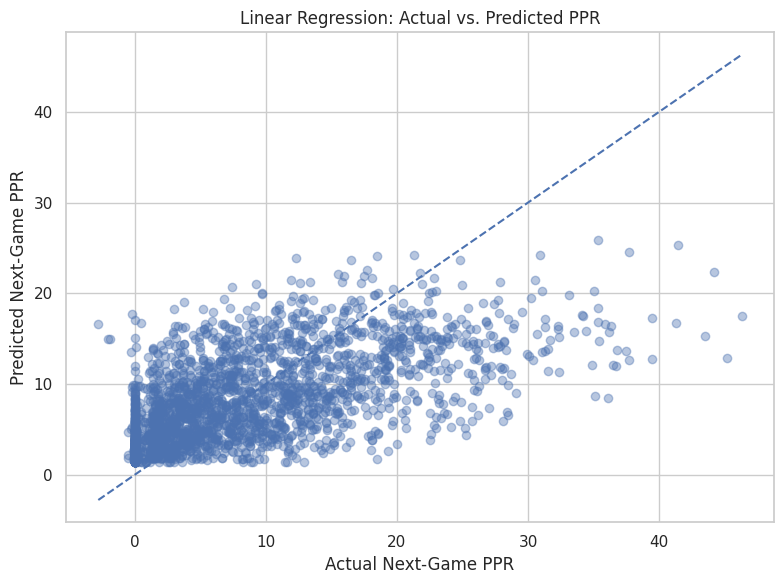

In [32]:
# Plot actual vs predicted PPR
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    linear_predictions,
    alpha=0.4
)

# Add reference line for perfect predictions
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Next-Game PPR")
plt.ylabel("Predicted Next-Game PPR")
plt.title("Linear Regression: Actual vs. Predicted PPR")

plt.tight_layout()
plt.show()

In [33]:
# Calculate Random Forest feature importance
feature_importance = pd.DataFrame(
    {
        "Feature": feature_columns,
        "Importance": rf_model.feature_importances_
    }
)

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display feature importance
print("Random Forest Feature Importance")
display(feature_importance.round(4))

Random Forest Feature Importance


,Feature,Importance
1,avg_ppr_last_3,0.7313
0,previous_game_ppr,0.0964
2,avg_targets_last_3,0.0748
3,avg_carries_last_3,0.0685
4,position_QB,0.0221
7,position_TE,0.0029
6,position_WR,0.0025
5,position_RB,0.0015


In [34]:

# Create a baseline using previous-game PPR
baseline_predictions = X_test["previous_game_ppr"]

# Evaluate baseline performance
baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(
    y_test,
    baseline_predictions
)

# Display results
print("Previous-Game Baseline Results")
print("------------------------------")
print("MAE:", round(baseline_mae, 2))
print("RMSE:", round(baseline_rmse, 2))
print("R² Score:", round(baseline_r2, 3))


Previous-Game Baseline Results
------------------------------
MAE: 5.77
RMSE: 8.16
R² Score: 0.007


In [35]:

# Compare model performance

model_comparison = pd.DataFrame({
    "Model": [
        "Previous-Game Baseline",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        rf_rmse
    ],
    "R2 Score": [
        baseline_r2,
        linear_r2,
        rf_r2
    ]
})

# Display comparison
model_comparison = model_comparison.round(3)

model_comparison




,Model,MAE,RMSE,R2 Score
0,Previous-Game Baseline,5.766,8.161,0.007
1,Linear Regression,4.784,6.383,0.393
2,Random Forest,4.843,6.504,0.369


### Position-Specific Model Evaluation

Overall model performance can hide differences between positions. The following table compares prediction error for quarterbacks, running backs, wide receivers, and tight ends in the held-out season.

In [36]:
# Evaluate prediction errors separately for each position.
position_columns = ["position_QB", "position_RB", "position_WR", "position_TE"]

test_positions = (
    test_data[position_columns]
    .idxmax(axis=1)
    .str.replace("position_", "", regex=False)
)

position_eval = pd.DataFrame(
    {
        "position": test_positions,
        "actual_ppr": y_test,
        "baseline_prediction": baseline_predictions,
        "linear_prediction": linear_predictions,
        "random_forest_prediction": rf_predictions
    },
    index=y_test.index
)

position_results = []

for position, group in position_eval.groupby("position"):
    actual = group["actual_ppr"]

    position_results.append({
        "Position": position,
        "Games": len(group),
        "Baseline MAE": mean_absolute_error(actual, group["baseline_prediction"]),
        "Linear Regression MAE": mean_absolute_error(actual, group["linear_prediction"]),
        "Random Forest MAE": mean_absolute_error(actual, group["random_forest_prediction"])
    })

position_model_comparison = pd.DataFrame(position_results)
display(position_model_comparison.round(3))

,Position,Games,Baseline MAE,Linear Regression MAE,Random Forest MAE
0,QB,246,8.538,6.585,6.920
1,RB,626,5.756,4.972,5.087
2,TE,564,5.039,4.080,4.068
3,WR,1053,5.514,4.629,4.628


### Machine Learning Findings

Three approaches are evaluated using the chronological train/test split:

- **Previous-Game Baseline:** Uses the player's previous recorded appearance as the prediction.
- **Linear Regression:** Uses recent PPR, recent workload, and player position to estimate next-appearance PPR.
- **Random Forest:** Captures nonlinear relationships among the same engineered features.

The overall model comparison reports MAE, RMSE, and R² for the held-out season. A position-specific MAE comparison is also included to show whether prediction errors differ across QB, RB, WR, and TE.

The final projection model is selected dynamically using the lowest held-out MAE and then refitted on all available labeled observations. Feature importance from Random Forest describes how the fitted model uses its inputs; it does not establish causal relationships.

## 6. Player Projections and Valuation

The model with the lowest MAE on the held-out latest season is refitted using all available labeled observations. It then estimates PPR for players with an appearance in the latest available season.

The player valuation score combines three position-relative percentiles:

- 50% projected next-appearance PPR.
- 30% average PPR in the latest season.
- 20% scoring consistency, where lower standard deviation receives a higher score.

These weights are transparent analyst-defined assumptions. Scores are intended to rank players **within the same position** and should not be added together or treated as universal trade-market values.

In [37]:
# Refit the best-performing model on all available labeled observations.

X_all = model_data[feature_columns]
y_all = model_data["next_game_ppr"]

if linear_mae <= rf_mae:
    selected_model_name = "Linear Regression"
    final_scaler = StandardScaler()
    X_all_fit = final_scaler.fit_transform(X_all)
    final_model = LinearRegression()
else:
    selected_model_name = "Random Forest"
    final_scaler = None
    X_all_fit = X_all
    final_model = RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        min_samples_split=5,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

final_model.fit(X_all_fit, y_all)

print("Selected final model:", selected_model_name)
print("Selection criterion: lowest MAE on the held-out latest season")
print("Training records:", len(X_all))
print("Training seasons:", sorted(model_data["season"].unique()))
print("Final model training complete.")

Selected final model: Linear Regression
Selection criterion: lowest MAE on the held-out latest season
Training records: 21417
Training seasons: [np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025), np.int32(2026)]
Final model training complete.


In [38]:
# Identify each player's most recent recorded appearance in the latest season.
latest_players = (
    fantasy_stats[fantasy_stats["season"] == latest_season]
    .sort_values(["player_id", "week"])
    .groupby("player_id", as_index=False)
    .tail(1)
    .copy()
)

# Align the latest-player features with the training feature columns.
latest_players_encoded = pd.get_dummies(
    latest_players,
    columns=["position"],
    dtype=int
)

X_latest = latest_players_encoded.reindex(
    columns=feature_columns,
    fill_value=0
)

# Remove records with incomplete prediction inputs.
valid_players = X_latest.notna().all(axis=1)
latest_players = latest_players.loc[valid_players].copy()
X_latest = X_latest.loc[valid_players]

# Apply scaling only when the selected model is Linear Regression.
if final_scaler is not None:
    X_latest_model_input = final_scaler.transform(X_latest)
else:
    X_latest_model_input = X_latest

latest_players["projected_next_game_ppr"] = final_model.predict(
    X_latest_model_input
)

player_projections = latest_players[
    [
        "player_id",
        "player_display_name",
        "position",
        "projected_next_game_ppr"
    ]
].copy()

player_projections = player_projections.sort_values(
    "projected_next_game_ppr",
    ascending=False
).reset_index(drop=True)

print("Projection model:", selected_model_name)
display(player_projections.head(20).round(2))

Projection model: Linear Regression


,player_id,player_display_name,position,projected_next_game_ppr
0,00-0036555,Chuba Hubbard,RB,21.25
1,00-0039139,Jahmyr Gibbs,RB,21.08
2,00-0040691,Jaxson Dart,QB,20.85
3,00-0035261,Tony Pollard,RB,20.84
4,00-0036442,Joe Burrow,QB,19.61
5,00-0036900,Ja'Marr Chase,WR,19.19
6,00-0036358,CeeDee Lamb,WR,19.00
7,00-0033280,Christian McCaffrey,RB,18.83
8,00-0039361,Bucky Irving,RB,18.83
9,00-0035700,Josh Jacobs,RB,18.64


In [39]:
# Confirm the season used for the player projection pool.
print("Latest season included:", latest_season)
print("Players with a latest-season appearance:", player_projections["player_id"].nunique())

Latest season included: 2026
Players with a latest-season appearance: 513


In [40]:
# Calculate player consistency using the latest available season.
latest_season_stats = fantasy_stats[
    fantasy_stats["season"] == latest_season
].copy()

player_consistency = (
    latest_season_stats
    .groupby(
        ["player_id", "player_display_name", "position"],
        as_index=False
    )
    .agg(
        games_played=("fantasy_points_ppr", "count"),
        avg_ppr=("fantasy_points_ppr", "mean"),
        std_ppr=("fantasy_points_ppr", "std"),
        median_ppr=("fantasy_points_ppr", "median")
    )
)

# Require at least three appearances for more stable player summaries.
player_consistency = player_consistency[
    (player_consistency["games_played"] >= 3) &
    (player_consistency["avg_ppr"] > 0)
].copy()

player_consistency = player_consistency.sort_values(
    "avg_ppr",
    ascending=False
).reset_index(drop=True)

display(player_consistency.head(15).round(2))

,player_id,player_display_name,position,games_played,avg_ppr,std_ppr,median_ppr
0,00-0039139,Jahmyr Gibbs,RB,10,28.12,10.72,26.30
1,00-0038543,Jaxon Smith-Njigba,WR,10,26.32,9.44,25.80
2,00-0036442,Joe Burrow,QB,9,25.81,7.98,24.60
3,00-0039075,Puka Nacua,WR,7,24.80,9.65,25.00
4,00-0038134,Kenneth Walker III,RB,8,24.55,9.71,25.85
5,00-0033280,Christian McCaffrey,RB,9,23.67,9.79,22.00
6,00-0034857,Josh Allen,QB,10,23.52,9.65,20.43
7,00-0036358,CeeDee Lamb,WR,11,22.93,11.32,20.20
8,00-0037834,Brock Purdy,QB,9,22.55,6.99,21.10
9,00-0033077,Dak Prescott,QB,11,21.61,8.42,19.50


In [41]:
# Combine next-appearance projections with latest-season performance metrics.
player_valuation = player_projections.merge(
    player_consistency[
        [
            "player_id",
            "games_played",
            "avg_ppr",
            "std_ppr",
            "median_ppr"
        ]
    ],
    on="player_id",
    how="inner",
    validate="one_to_one"
)

player_valuation = player_valuation[
    [
        "player_id",
        "player_display_name",
        "position",
        "projected_next_game_ppr",
        "games_played",
        "avg_ppr",
        "std_ppr",
        "median_ppr"
    ]
].copy()

player_valuation = player_valuation.sort_values(
    "projected_next_game_ppr",
    ascending=False
).reset_index(drop=True)

print("Player valuation records:", len(player_valuation))
display(player_valuation.head(20).round(2))

Player valuation records: 441


,player_id,player_display_name,position,projected_next_game_ppr,games_played,avg_ppr,std_ppr,median_ppr
0,00-0036555,Chuba Hubbard,RB,21.25,10,20.68,7.48,21.40
1,00-0039139,Jahmyr Gibbs,RB,21.08,10,28.12,10.72,26.30
2,00-0035261,Tony Pollard,RB,20.84,10,15.14,10.91,12.00
3,00-0036442,Joe Burrow,QB,19.61,9,25.81,7.98,24.60
4,00-0036900,Ja'Marr Chase,WR,19.19,9,21.53,11.14,24.80
5,00-0036358,CeeDee Lamb,WR,19.00,11,22.93,11.32,20.20
6,00-0033280,Christian McCaffrey,RB,18.83,9,23.67,9.79,22.00
7,00-0039361,Bucky Irving,RB,18.83,10,17.81,9.05,19.65
8,00-0035700,Josh Jacobs,RB,18.64,3,14.60,12.31,20.10
9,00-0033077,Dak Prescott,QB,18.31,11,21.61,8.42,19.50


In [42]:
# Check the merged player valuation dataset

print("Player projections shape:", player_projections.shape)
print("Player consistency shape:", player_consistency.shape)
print("Player valuation shape:", player_valuation.shape)

print("\nPlayer valuation columns:")
print(player_valuation.columns.tolist())

player_valuation.head(10)

Player projections shape: (513, 4)
Player consistency shape: (441, 7)
Player valuation shape: (441, 8)

Player valuation columns:
['player_id', 'player_display_name', 'position', 'projected_next_game_ppr', 'games_played', 'avg_ppr', 'std_ppr', 'median_ppr']


,player_id,player_display_name,position,projected_next_game_ppr,games_played,avg_ppr,std_ppr,median_ppr
0,00-0036555,Chuba Hubbard,RB,21.245587,10,20.680000,7.480761,21.40
1,00-0039139,Jahmyr Gibbs,RB,21.082476,10,28.120000,10.715596,26.30
2,00-0035261,Tony Pollard,RB,20.844476,10,15.140000,10.905269,12.00
3,00-0036442,Joe Burrow,QB,19.612649,9,25.811111,7.976165,24.60
4,00-0036900,Ja'Marr Chase,WR,19.189666,9,21.533333,11.141477,24.80
5,00-0036358,CeeDee Lamb,WR,18.999880,11,22.927273,11.316633,20.20
6,00-0033280,Christian McCaffrey,RB,18.834089,9,23.666667,9.794897,22.00
7,00-0039361,Bucky Irving,RB,18.830256,10,17.810000,9.051022,19.65
8,00-0035700,Josh Jacobs,RB,18.635728,3,14.600000,12.308940,20.10
9,00-0033077,Dak Prescott,QB,18.310903,11,21.614545,8.421886,19.50


In [43]:
# Calculate position-relative player value scores.
# Scores are percentile-based within each position, not across positions.

player_valuation["projection_rank"] = (
    player_valuation.groupby("position")["projected_next_game_ppr"]
    .rank(pct=True, ascending=True)
)

player_valuation["performance_rank"] = (
    player_valuation.groupby("position")["avg_ppr"]
    .rank(pct=True, ascending=True)
)

# Lower scoring standard deviation receives a higher consistency percentile.
player_valuation["consistency_rank"] = (
    player_valuation.groupby("position")["std_ppr"]
    .rank(pct=True, ascending=False)
)

# Analyst-defined weights: 50% projection, 30% historical PPR, 20% consistency.
player_valuation["player_value_score"] = (
    0.50 * player_valuation["projection_rank"] +
    0.30 * player_valuation["performance_rank"] +
    0.20 * player_valuation["consistency_rank"]
) * 100

player_valuation = player_valuation.sort_values(
    "player_value_score",
    ascending=False
).reset_index(drop=True)

display(
    player_valuation[
        [
            "player_display_name",
            "position",
            "projected_next_game_ppr",
            "avg_ppr",
            "std_ppr",
            "player_value_score"
        ]
    ].head(20).round(2)
)

,player_display_name,position,projected_next_game_ppr,avg_ppr,std_ppr,player_value_score
0,Joe Burrow,QB,19.61,25.81,7.98,86.22
1,James Cook,RB,16.49,18.73,4.11,86.21
2,C.J. Stroud,QB,16.99,20.49,6.29,85.33
3,Chuba Hubbard,RB,21.25,20.68,7.48,83.19
4,Rashee Rice,WR,11.49,12.96,3.12,82.63
5,Matthew Golden,WR,17.81,17.59,7.17,82.63
6,Trey McBride,TE,11.13,16.94,5.96,81.88
7,Dak Prescott,QB,18.31,21.61,8.42,81.78
8,Brock Purdy,QB,16.48,22.55,6.99,81.11
9,Jordan Love,QB,17.07,19.58,7.25,81.11


In [44]:
# Rank players within their respective positions

player_valuation["position_rank"] = (
    player_valuation.groupby("position")[
        "player_value_score"
    ].rank(
        method="dense",
        ascending=False
    ).astype(int)
)

# Sort by position and rank
player_valuation = player_valuation.sort_values(
    ["position", "position_rank"]
).reset_index(drop=True)

# Display the top 10 players at each position
for position in ["QB", "RB", "WR", "TE"]:

    print(f"\nTop 10 {position} Players")

    display(
        player_valuation[
            player_valuation["position"] == position
        ][
            [
                "player_display_name",
                "position_rank",
                "projected_next_game_ppr",
                "avg_ppr",
                "std_ppr",
                "player_value_score"
            ]
        ].head(10)
    )


Top 10 QB Players


,player_display_name,position_rank,projected_next_game_ppr,avg_ppr,std_ppr,player_value_score
0,Joe Burrow,1,19.612649,25.811111,7.976165,86.222222
1,C.J. Stroud,2,16.994908,20.494000,6.288346,85.333333
2,Dak Prescott,3,18.310903,21.614545,8.421886,81.777778
3,Brock Purdy,4,16.475994,22.551111,6.992490,81.111111
4,Jordan Love,5,17.072305,19.582000,7.250137,81.111111
5,Josh Allen,6,17.433503,23.518000,9.647574,78.666667
6,Patrick Mahomes,7,17.848383,20.236000,8.814855,78.444444
7,Kirk Cousins,8,16.115117,18.768000,4.935290,78.222222
8,Trevor Lawrence,9,15.727138,19.328889,7.220499,70.666667
9,Jayden Daniels,10,15.277264,19.422857,6.291406,69.555556



Top 10 RB Players


,player_display_name,position_rank,projected_next_game_ppr,avg_ppr,std_ppr,player_value_score
45,James Cook,1,16.485041,18.730000,4.113676,86.206897
46,Chuba Hubbard,2,21.245587,20.680000,7.480761,83.189655
47,Jahmyr Gibbs,3,21.082476,28.120000,10.715596,80.603448
48,Christian McCaffrey,4,18.834089,23.666667,9.794897,79.741379
49,Bucky Irving,5,18.830256,17.810000,9.051022,79.310345
50,Kenneth Walker III,6,15.911950,24.550000,9.710672,78.017241
51,Bijan Robinson,7,17.017663,19.770000,9.946864,77.758621
52,Breece Hall,8,12.457108,14.666667,4.294027,76.724138
53,Javonte Williams,9,13.962361,17.400000,8.083935,76.465517
54,D'Andre Swift,10,15.032489,16.570000,9.194449,76.034483



Top 10 WR Players


,player_display_name,position_rank,projected_next_game_ppr,avg_ppr,std_ppr,player_value_score
262,Rashee Rice,1,11.487426,12.957143,3.124024,82.625698
263,Matthew Golden,1,17.811949,17.590000,7.168829,82.625698
264,Jaxon Smith-Njigba,2,17.107772,26.316000,9.435224,80.335196
265,Ja'Marr Chase,3,19.189666,21.533333,11.141477,80.167598
266,CeeDee Lamb,4,18.999880,22.927273,11.316633,79.944134
267,DeVonta Smith,5,17.168860,15.620000,8.300120,79.888268
268,Puka Nacua,6,15.951633,24.800000,9.646243,79.217877
269,Mike Evans,7,13.612105,14.833333,6.228536,78.826816
270,Amon-Ra St. Brown,8,13.753705,19.810000,8.085165,78.547486
271,Tee Higgins,9,16.211909,19.044444,10.391476,78.268156



Top 10 TE Players


,player_display_name,position_rank,projected_next_game_ppr,avg_ppr,std_ppr,player_value_score
161,Trey McBride,1,11.133879,16.936364,5.963769,81.881188
162,George Kittle,2,12.354940,14.188889,6.778356,80.792079
163,Brock Bowers,3,15.001945,18.725000,8.577171,80.594059
164,Colston Loveland,4,12.735685,9.520000,6.653120,79.207921
165,Harold Fannin Jr.,5,12.428888,11.840000,7.983344,78.316832
166,Chig Okonkwo,6,9.371016,7.328571,4.556210,78.019802
167,Isaiah Likely,7,11.587355,17.388889,11.070281,77.920792
168,AJ Barner,8,9.025770,6.770000,4.069412,77.326733
169,Tucker Kraft,9,8.878988,9.330000,5.660987,76.435644
170,Dalton Kincaid,10,9.431380,10.300000,7.611997,75.841584


### Interactive Player Valuation Visualizations

Plotly charts allow users to hover over players to inspect their projected PPR, latest-season performance, consistency, and position-relative valuation. Because valuation scores are calculated within each position, player rankings are displayed separately by position rather than as a universal cross-position ranking.


In [45]:
# Interactive position-relative player valuation charts
# Show the top 10 players within each position.

top_by_position = (
    player_valuation
    .sort_values(["position", "player_value_score"], ascending=[True, False])
    .groupby("position", group_keys=False)
    .head(10)
    .copy()
)

fig = px.bar(
    top_by_position.sort_values("player_value_score"),
    x="player_value_score",
    y="player_display_name",
    color="position",
    facet_col="position",
    facet_col_wrap=2,
    orientation="h",
    hover_data={
        "position": True,
        "projected_next_game_ppr": ":.2f",
        "avg_ppr": ":.2f",
        "std_ppr": ":.2f",
        "player_value_score": ":.2f"
    },
    title="Top 10 Players by Position-Relative Value Score",
    labels={
        "player_value_score": "Position-Relative Value Score",
        "player_display_name": "Player",
        "position": "Position",
        "projected_next_game_ppr": "Projected Next-Game PPR",
        "avg_ppr": "Latest-Season Average PPR",
        "std_ppr": "PPR Standard Deviation"
    }
)

fig.update_layout(
    height=850,
    showlegend=False,
    xaxis_title="Position-Relative Value Score",
    yaxis_title="Player"
)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()


In [46]:
# Interactive comparison of historical average PPR and projected next-game PPR

fig = px.scatter(
    player_valuation,
    x="avg_ppr",
    y="projected_next_game_ppr",
    color="position",
    size="games_played",
    hover_name="player_display_name",
    hover_data={
        "games_played": True,
        "avg_ppr": ":.2f",
        "projected_next_game_ppr": ":.2f",
        "std_ppr": ":.2f",
        "player_value_score": ":.2f"
    },
    title="Historical Average PPR vs. Projected Next-Game PPR",
    labels={
        "avg_ppr": "Latest-Season Average PPR",
        "projected_next_game_ppr": "Projected Next-Game PPR",
        "position": "Position",
        "games_played": "Games Played"
    }
)

axis_min = min(
    player_valuation["avg_ppr"].min(),
    player_valuation["projected_next_game_ppr"].min()
)
axis_max = max(
    player_valuation["avg_ppr"].max(),
    player_valuation["projected_next_game_ppr"].max()
)

fig.add_shape(
    type="line",
    x0=axis_min,
    y0=axis_min,
    x1=axis_max,
    y1=axis_max,
    line=dict(dash="dash", color="gray")
)

fig.update_layout(height=650)
fig.show()


## Final Interactive Fantasy Football Dashboard

This dashboard brings the player valuation results together in one interactive view. It uses the current `player_valuation` dataset and the project's PPR-based metrics.

The dashboard includes:
- Position-relative player rankings (top five at each position).
- Historical average PPR compared with projected next-appearance PPR.
- Average projected PPR by position.
- Average scoring variability by position.

**Important:** Player value scores are calculated within each position. The dashboard therefore shows position rankings as separate groups and does not treat a QB's score as directly comparable to a WR's score.

In [47]:
# Build a single, interactive Plotly dashboard from the current player valuation data.

# Top five players within each position.
dashboard_top_players = (
    player_valuation
    .sort_values(["position", "player_value_score"], ascending=[True, False])
    .groupby("position", group_keys=False)
    .head(5)
    .copy()
)

# Position-level summary metrics.
position_dashboard = (
    player_valuation
    .groupby("position", as_index=False)
    .agg(
        avg_projected_ppr=("projected_next_game_ppr", "mean"),
        avg_historical_ppr=("avg_ppr", "mean"),
        avg_volatility=("std_ppr", "mean"),
        player_count=("player_id", "nunique")
    )
)

# Create a 2x2 dashboard layout.
fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Top Five Players by Position-Relative Value",
        "Historical Average PPR vs. Projected PPR",
        "Average Projected PPR by Position",
        "Average Weekly PPR Variability by Position"
    ),
    horizontal_spacing=0.12,
    vertical_spacing=0.16
)

# Panel 1: Top five player rankings, grouped by position.
for position in ["QB", "RB", "WR", "TE"]:
    position_players = dashboard_top_players[
        dashboard_top_players["position"] == position
    ].sort_values("player_value_score", ascending=True)

    fig.add_trace(
        go.Bar(
            x=position_players["player_value_score"],
            y=position_players["player_display_name"],
            name=position,
            orientation="h",
            legendgroup=position,
            showlegend=True,
            customdata=position_players[
                ["projected_next_game_ppr", "avg_ppr", "std_ppr"]
            ],
            hovertemplate=(
                "<b>%{y}</b><br>"
                "Position: " + position + "<br>"
                "Position-relative value score: %{x:.1f}<br>"
                "Projected next-appearance PPR: %{customdata[0]:.2f}<br>"
                "Latest-season average PPR: %{customdata[1]:.2f}<br>"
                "PPR standard deviation: %{customdata[2]:.2f}"
                "<extra></extra>"
            )
        ),
        row=1,
        col=1
    )

# Panel 2: Player-level historical vs projected PPR.
for position in ["QB", "RB", "WR", "TE"]:
    position_players = player_valuation[
        player_valuation["position"] == position
    ]

    fig.add_trace(
        go.Scatter(
            x=position_players["avg_ppr"],
            y=position_players["projected_next_game_ppr"],
            mode="markers",
            name=position,
            legendgroup=position,
            showlegend=False,
            marker=dict(size=9),
            text=position_players["player_display_name"],
            customdata=position_players[["games_played", "std_ppr"]],
            hovertemplate=(
                "<b>%{text}</b><br>"
                "Position: " + position + "<br>"
                "Latest-season average PPR: %{x:.2f}<br>"
                "Projected next-appearance PPR: %{y:.2f}<br>"
                "Games played: %{customdata[0]}<br>"
                "PPR standard deviation: %{customdata[1]:.2f}"
                "<extra></extra>"
            )
        ),
        row=1,
        col=2
    )

# Panel 3: Average projected PPR by position.
fig.add_trace(
    go.Bar(
        x=position_dashboard["position"],
        y=position_dashboard["avg_projected_ppr"],
        name="Average projected PPR",
        marker=dict(),
        showlegend=False,
        customdata=position_dashboard[["player_count", "avg_historical_ppr"]],
        hovertemplate=(
            "<b>%{x}</b><br>"
            "Average projected PPR: %{y:.2f}<br>"
            "Players evaluated: %{customdata[0]}<br>"
            "Average historical PPR: %{customdata[1]:.2f}"
            "<extra></extra>"
        )
    ),
    row=2,
    col=1
)

# Panel 4: Average standard deviation by position (lower means more consistent).
fig.add_trace(
    go.Bar(
        x=position_dashboard["position"],
        y=position_dashboard["avg_volatility"],
        name="Average PPR standard deviation",
        marker=dict(),
        showlegend=False,
        hovertemplate=(
            "<b>%{x}</b><br>"
            "Average PPR standard deviation: %{y:.2f}"
            "<extra></extra>"
        )
    ),
    row=2,
    col=2
)

fig.update_xaxes(title_text="Position-relative value score", row=1, col=1)
fig.update_yaxes(title_text="Player", row=1, col=1)
fig.update_xaxes(title_text="Latest-season average PPR", row=1, col=2)
fig.update_yaxes(title_text="Projected next-appearance PPR", row=1, col=2)
fig.update_xaxes(title_text="Position", row=2, col=1)
fig.update_yaxes(title_text="Average projected PPR", row=2, col=1)
fig.update_xaxes(title_text="Position", row=2, col=2)
fig.update_yaxes(title_text="Average PPR standard deviation", row=2, col=2)

fig.update_layout(
    title={
        "text": "NFL Fantasy Football — Player Valuation Dashboard",
        "x": 0.5,
        "xanchor": "center"
    },
    height=950,
    template="plotly_white",
    hovermode="closest",
    barmode="group",
    legend_title_text="Position"
)

fig.show()

# Display compact dashboard summary metrics.
print("Dashboard Summary")
print("-----------------")
print("Players evaluated:", player_valuation["player_id"].nunique())
print("Latest season analyzed:", latest_season)
print("Selected prediction model:", selected_model_name)
print("Best held-out MAE:", round(min(linear_mae, rf_mae), 3))
print("Positions represented:", ", ".join(sorted(player_valuation["position"].unique())))


Dashboard Summary
-----------------
Players evaluated: 441
Latest season analyzed: 2026
Selected prediction model: Linear Regression
Best held-out MAE: 4.784
Positions represented: QB, RB, TE, WR


## 7. Interactive Trade Analyzer

The trade analyzer accepts multiple players on both sides of a proposed trade and the user's full current roster. It optimizes the starting lineup before and after the trade using projected PPR, supports multiple FLEX positions, reports bench changes, and identifies whether incoming players address selected roster needs.

The default lineup is one QB, two RB, two WR, one TE, and one FLEX (RB/WR/TE). Users can change each slot count to match their league.

In [ ]:
# ==========================================================
# NFL FANTASY FOOTBALL TRADE ANALYZER
# Starting Lineup Impact + Roster Needs + Bench Analysis
# ==========================================================

# Build a case-insensitive player lookup.
player_lookup = {
    str(name).strip().casefold(): name
    for name in player_valuation["player_display_name"].dropna().unique()
}


def get_players(prompt):
    """Collect one or more valid player names, separated by commas."""
    while True:
        user_input = input(prompt).strip()
        names = [name.strip() for name in user_input.split(",") if name.strip()]

        if not names:
            print("Please enter at least one player.")
            continue

        normalized = [name.casefold() for name in names]
        if len(normalized) != len(set(normalized)):
            print("Duplicate players detected. Please enter each player once.")
            continue

        unknown = [name for name in names if name.casefold() not in player_lookup]
        if unknown:
            print("Players not found in the current player valuation pool:", unknown)
            print("Use a player name shown in the player valuation tables.")
            continue

        return [player_lookup[name.casefold()] for name in names]


print("=" * 60)
print("NFL FANTASY FOOTBALL TRADE ANALYZER")
print("=" * 60)

# Collect trade packages.
players_giving = get_players("\nEnter the player(s) YOU ARE GIVING UP: ")
players_receiving = get_players("Enter the player(s) YOU ARE RECEIVING: ")

while set(players_giving).intersection(players_receiving):
    print("The same player cannot appear on both sides of a trade.")
    players_receiving = get_players("Re-enter the player(s) YOU ARE RECEIVING: ")

# Collect the current roster.
print("\n===== CURRENT FANTASY ROSTER =====")
print("Enter your entire current roster, including every player you are giving up.")
current_roster = get_players("\nEnter your roster players separated by commas: ")

while not set(players_giving).issubset(set(current_roster)):
    missing_give = sorted(set(players_giving) - set(current_roster))
    print("Your roster is missing the player(s) being traded away:", missing_give)
    current_roster = get_players("Re-enter your current roster: ")

while set(players_receiving).intersection(current_roster):
    already_owned = sorted(set(players_receiving).intersection(current_roster))
    print("You already have these incoming player(s) on your roster:", already_owned)
    players_receiving = get_players("Re-enter the player(s) YOU ARE RECEIVING: ")
    while set(players_giving).intersection(players_receiving):
        print("The same player cannot appear on both sides of a trade.")
        players_receiving = get_players("Re-enter the player(s) YOU ARE RECEIVING: ")

# Collect configurable starting lineup settings.
print("\n===== LEAGUE STARTING LINEUP SETTINGS =====")
print("Press Enter to use the default PPR lineup settings.\n")


def get_slot_count(position, default):
    while True:
        value = input(f"Starting {position} slots [{default}]: ").strip()
        if value == "":
            return default
        try:
            count = int(value)
            if count < 0:
                print("Enter zero or a positive whole number.")
                continue
            return count
        except ValueError:
            print("Please enter a whole number.")


lineup_settings = {
    "QB": get_slot_count("QB", 1),
    "RB": get_slot_count("RB", 2),
    "WR": get_slot_count("WR", 2),
    "TE": get_slot_count("TE", 1),
    "FLEX": get_slot_count("FLEX (RB/WR/TE)", 1)
}

while sum(lineup_settings.values()) == 0:
    print("Your lineup must contain at least one starting position.")
    lineup_settings = {
        "QB": get_slot_count("QB", 1),
        "RB": get_slot_count("RB", 2),
        "WR": get_slot_count("WR", 2),
        "TE": get_slot_count("TE", 1),
        "FLEX": get_slot_count("FLEX (RB/WR/TE)", 1)
    }

# Collect roster needs.
print("\n===== ROSTER NEEDS =====")
valid_positions = {"QB", "RB", "WR", "TE"}

while True:
    roster_input = input(
        "Which positions need help? (QB, RB, WR, TE; separate with commas; enter None): "
    ).strip()

    if roster_input.casefold() == "none" or roster_input == "":
        roster_needs = []
        break

    requested_positions = [
        position.strip().upper()
        for position in roster_input.split(",")
        if position.strip()
    ]
    invalid_positions = sorted(set(requested_positions) - valid_positions)

    if invalid_positions:
        print("Invalid positions:", invalid_positions)
        continue

    roster_needs = list(dict.fromkeys(requested_positions))
    break


def get_roster_data(player_names):
    """Return one valuation record per player and validate the lookup."""
    roster_data = player_valuation[
        player_valuation["player_display_name"].isin(player_names)
    ].copy()

    found_names = set(roster_data["player_display_name"])
    missing_names = set(player_names) - found_names

    if missing_names:
        raise ValueError(f"Could not retrieve player records for: {sorted(missing_names)}")

    return roster_data.drop_duplicates(subset="player_id")


before_roster = get_roster_data(current_roster)
after_roster_names = (
    [name for name in current_roster if name not in players_giving]
    + players_receiving
)
after_roster = get_roster_data(after_roster_names)


def build_starting_lineup(roster, settings):
    """Fill dedicated positions first, then fill all FLEX slots."""
    available = roster.sort_values(
        "projected_next_game_ppr", ascending=False
    ).copy()

    selected_ids = set()

    for position in ["QB", "RB", "WR", "TE"]:
        position_players = available[available["position"] == position]
        selected_ids.update(
            position_players.head(settings[position])["player_id"].tolist()
        )

    remaining = available[~available["player_id"].isin(selected_ids)]
    flex_candidates = remaining[
        remaining["position"].isin(["RB", "WR", "TE"])
    ].sort_values("projected_next_game_ppr", ascending=False)

    selected_ids.update(
        flex_candidates.head(settings["FLEX"])["player_id"].tolist()
    )

    starters = available[available["player_id"].isin(selected_ids)].copy()
    bench = available[~available["player_id"].isin(selected_ids)].copy()

    unfilled_slots = max(0, sum(settings.values()) - len(starters))
    return starters, bench, unfilled_slots


before_starters, before_bench, before_unfilled = build_starting_lineup(
    before_roster, lineup_settings
)
after_starters, after_bench, after_unfilled = build_starting_lineup(
    after_roster, lineup_settings
)


def lineup_summary(lineup, unfilled_slots):
    if lineup.empty:
        return {
            "projected_ppr": 0.0,
            "average_ppr": np.nan,
            "average_volatility": np.nan,
            "number_of_starters": 0,
            "unfilled_slots": unfilled_slots
        }

    return {
        "projected_ppr": lineup["projected_next_game_ppr"].sum(),
        "average_ppr": lineup["avg_ppr"].mean(),
        "average_volatility": lineup["std_ppr"].mean(),
        "number_of_starters": len(lineup),
        "unfilled_slots": unfilled_slots
    }


before_stats = lineup_summary(before_starters, before_unfilled)
after_stats = lineup_summary(after_starters, after_unfilled)

lineup_difference = after_stats["projected_ppr"] - before_stats["projected_ppr"]
volatility_difference = (
    after_stats["average_volatility"] - before_stats["average_volatility"]
)

display_columns = [
    "player_display_name",
    "position",
    "projected_next_game_ppr",
    "avg_ppr",
    "std_ppr",
    "player_value_score"
]

# Show the trade packages without summing position-relative value scores.
giving_data = get_roster_data(players_giving)
receiving_data = get_roster_data(players_receiving)

print("\n===== PLAYERS YOU ARE GIVING UP =====")
display(giving_data[display_columns].round(2))

print("\n===== PLAYERS YOU ARE RECEIVING =====")
display(receiving_data[display_columns].round(2))

giving_projection = giving_data["projected_next_game_ppr"].sum()
receiving_projection = receiving_data["projected_next_game_ppr"].sum()

print("\nTrade package projected PPR:")
print(f"Players given up: {giving_projection:.2f}")
print(f"Players received: {receiving_projection:.2f}")
print(f"Difference (received - given): {receiving_projection - giving_projection:+.2f}")

# Display optimized lineups and benches.
print("\n" + "=" * 60)
print("STARTING LINEUP BEFORE TRADE")
print("=" * 60)
display(
    before_starters[display_columns]
    .sort_values(["position", "projected_next_game_ppr"], ascending=[True, False])
    .round(2)
)
print(f"Starting lineup projected PPR: {before_stats['projected_ppr']:.2f}")
print(f"Unfilled starting spots: {before_stats['unfilled_slots']}")

print("\n" + "=" * 60)
print("STARTING LINEUP AFTER TRADE")
print("=" * 60)
display(
    after_starters[display_columns]
    .sort_values(["position", "projected_next_game_ppr"], ascending=[True, False])
    .round(2)
)
print(f"Starting lineup projected PPR: {after_stats['projected_ppr']:.2f}")
print(f"Unfilled starting spots: {after_stats['unfilled_slots']}")

print("\n===== BENCH BEFORE TRADE =====")
display(before_bench[display_columns].round(2))

print("\n===== BENCH AFTER TRADE =====")
display(after_bench[display_columns].round(2))

# Starting lineup impact.
print("\n" + "=" * 60)
print("STARTING LINEUP IMPACT")
print("=" * 60)
print(f"Projected PPR before trade: {before_stats['projected_ppr']:.2f}")
print(f"Projected PPR after trade:  {after_stats['projected_ppr']:.2f}")
print(f"Starting lineup PPR change: {lineup_difference:+.2f}")

# Position-by-position roster breakdown.
print("\n===== POSITION BREAKDOWN =====")
position_results = []

for position in ["QB", "RB", "WR", "TE"]:
    before_position = before_roster[before_roster["position"] == position]
    after_position = after_roster[after_roster["position"] == position]

    position_results.append({
        "Position": position,
        "Roster Before": len(before_position),
        "Roster After": len(after_position),
        "PPR Before": before_position["projected_next_game_ppr"].sum(),
        "PPR After": after_position["projected_next_game_ppr"].sum()
    })

display(pd.DataFrame(position_results).round(2))

# Roster-needs analysis.
print("\n===== ROSTER NEEDS ANALYSIS =====")
incoming_need_players = after_roster[
    after_roster["player_display_name"].isin(players_receiving)
    & after_roster["position"].isin(roster_needs)
]

if roster_needs:
    print("Positions you need:", ", ".join(roster_needs))
    if not incoming_need_players.empty:
        print("Incoming players addressing your selected needs:")
        display(
            incoming_need_players[
                ["player_display_name", "position", "projected_next_game_ppr"]
            ].round(2)
        )
    else:
        print("The incoming players do not directly address your selected needs.")
else:
    print("No specific roster needs selected.")

# Starting-lineup reliability analysis.
print("\n===== STARTING LINEUP RELIABILITY =====")
if pd.notna(volatility_difference):
    print(f"Average volatility before: {before_stats['average_volatility']:.2f}")
    print(f"Average volatility after:  {after_stats['average_volatility']:.2f}")
    print(f"Volatility change:         {volatility_difference:+.2f}")

    if volatility_difference < 0:
        print("Reliability advantage: average historical scoring variability decreases.")
    elif volatility_difference > 0:
        print("Reliability concern: average historical scoring variability increases.")
    else:
        print("Average starting-lineup volatility is unchanged.")
else:
    print("Reliability comparison is unavailable because one lineup has no starters.")

# Final recommendation. The cutoffs are analyst-defined heuristics.
print("\n" + "=" * 60)
print("FINAL TRADE RECOMMENDATION")
print("=" * 60)

if lineup_difference >= 5:
    verdict = "LEAN ACCEPT"
    print("LEAN ACCEPT - The starting lineup gains at least 5 projected PPR points.")
elif lineup_difference <= -5:
    verdict = "LEAN REJECT"
    print("LEAN REJECT - The starting lineup loses at least 5 projected PPR points.")
else:
    verdict = "CLOSE TRADE"
    print("CLOSE TRADE - The projected starting-lineup difference is relatively small.")

if not incoming_need_players.empty:
    print("ROSTER ADVANTAGE - Incoming players address at least one selected roster need.")

if pd.notna(volatility_difference):
    if volatility_difference < 0:
        print("RELIABILITY ADVANTAGE - Average starting-lineup volatility decreases.")
    elif volatility_difference > 0:
        print("RELIABILITY CONCERN - Average starting-lineup volatility increases.")

if before_unfilled or after_unfilled:
    print("LINEUP DEPTH NOTE - At least one roster cannot fill every configured starting spot.")

# Final summary and assumptions.
print("\n===== TRADE SUMMARY =====")
print("Recommendation:", verdict)
print(f"Starting lineup PPR change: {lineup_difference:+.2f}")
print(f"Starting lineup volatility change: {volatility_difference:+.2f}")
print(f"Starters before: {before_stats['number_of_starters']}")
print(f"Starters after:  {after_stats['number_of_starters']}")

print("\nIMPORTANT NOTES:")
print("- Starting lineups are optimized using projected next-appearance PPR.")
print("- FLEX eligibility is limited to RB, WR, and TE.")
print("- Multiple FLEX slots are supported.")
print("- Player value scores are position-relative and are not summed across positions.")
print("- The +/-5 PPR recommendation thresholds are analyst-defined heuristics.")
print("- Projections estimate the next recorded appearance, not a guaranteed next-week result.")
print("- Injuries, confirmed availability, depth-chart changes, weather, and matchup difficulty are not modeled.")
print("- Roster needs and historical volatility provide context; they do not independently determine the verdict.")

# Interactive Plotly comparison of the players involved in this trade.
trade_chart_data = pd.concat(
    [
        giving_data.assign(trade_side="Giving"),
        receiving_data.assign(trade_side="Receiving")
    ],
    ignore_index=True
)

fig = px.bar(
    trade_chart_data,
    x="player_display_name",
    y="projected_next_game_ppr",
    color="trade_side",
    hover_data={
        "position": True,
        "projected_next_game_ppr": ":.2f",
        "avg_ppr": ":.2f",
        "std_ppr": ":.2f",
        "trade_side": True
    },
    barmode="group",
    title="Trade Package Comparison: Projected Next-Game PPR",
    labels={
        "player_display_name": "Player",
        "projected_next_game_ppr": "Projected Next-Game PPR",
        "trade_side": "Trade Side",
        "position": "Position",
        "avg_ppr": "Latest-Season Average PPR",
        "std_ppr": "PPR Standard Deviation"
    }
)

fig.update_layout(
    height=550,
    xaxis_title="Player",
    yaxis_title="Projected Next-Game PPR",
    legend_title="Trade Side"
)
fig.show()


NFL FANTASY FOOTBALL TRADE ANALYZER


## 8. Results & Key Findings

The project combines NFL player statistics, exploratory data analysis, predictive modeling, and an interactive trade evaluation workflow.

The analysis provides several findings:

- **Production and usage:** PPR production varies by position, and workload measures such as receiving targets and running back carries are useful indicators when examining player performance.
- **Scoring consistency:** Standard deviation and median PPR provide context beyond average production by showing how variable a player's weekly results can be.
- **Predictive modeling:** Linear Regression and Random Forest are evaluated against a previous-game baseline using a chronological holdout season. The model comparison table reports the measured performance for the current run.
- **Player projections:** The selected model estimates PPR for a player's next recorded appearance using historical production and workload features.
- **Player valuation:** A position-relative score combines projected PPR (50%), latest-season average PPR (30%), and scoring consistency (20%).
- **Trade evaluation:** The interactive analyzer compares multi-player trade packages and measures how the trade changes the team's optimized starting lineup.
- **Roster context:** Configurable starting positions, multiple FLEX slots, bench depth, and selected roster needs provide additional context for evaluating a trade.

The starting-lineup impact is especially important because a trade can improve a team's total player value without necessarily improving the players who will actually occupy its starting positions.

The player value score and recommendation thresholds are transparent analytical assumptions. They should be interpreted as decision-support measures rather than validated market prices or guarantees of trade success.

## 9. Limitations

Several limitations should be considered when interpreting the results:

- **Prediction error:** The machine learning model does not predict every player's weekly production accurately. Its MAE, RMSE, and R² should be interpreted using the held-out latest season.
- **Prediction target:** The model predicts PPR in the next recorded player appearance. This may be separated from the prior appearance by a bye week or missed games and is not necessarily the next calendar week.
- **Historical sample:** The current-season dataset may be incomplete because the NFL season is still in progress. Player performance and roles can change as additional games become available.
- **Minimum sample size:** The player valuation pool requires at least three games in the latest season. Players with fewer appearances are excluded, even if they may be relevant to a real fantasy roster.
- **Player availability:** Injuries, suspensions, depth-chart changes, coaching decisions, and changes in playing time are not directly incorporated into the model.
- **Valuation weights:** The 50% projection, 30% historical production, and 20% consistency weights are analyst-defined. They have not been optimized against historical fantasy trade outcomes.
- **Position-relative scores:** Player value scores are calculated within each position. They should not be treated as directly comparable across positions or summed to produce a trade-package value.
- **Starting lineup assumptions:** The lineup optimizer supports dedicated QB, RB, WR, and TE slots plus RB/WR/TE FLEX slots. It does not currently model every league format, such as superflex, IDP, tight-end premium, or custom scoring rules.
- **Recommendation thresholds:** The +5 and -5 projected PPR thresholds are heuristics. They are not statistically validated cutoffs for accepting or rejecting trades.
- **Matchup difficulty:** The current player projection and trade evaluation workflow does not incorporate an upcoming opponent-adjusted matchup projection.
- **Historical trade outcomes:** The trade scoring framework has not been validated against completed fantasy football trades or season-long league results.

The analyzer should therefore be treated as a structured decision-support tool, not as a guarantee of future player performance or trade success.

## 10. Conclusion

This project developed a Python-based fantasy football analytics and trade evaluation system using multi-season NFL player statistics.

The workflow begins with data collection, cleaning, and exploratory analysis. Historical player statistics are then transformed into predictive features and used to evaluate Linear Regression and Random Forest models against a previous-game baseline.

The selected predictive model estimates PPR points for a player's next recorded appearance. These projections are combined with latest-season production and scoring consistency to create position-relative player valuations.

The interactive trade analyzer builds on this work by allowing users to enter multi-player trades, configure league starting lineup requirements, and compare optimized lineups before and after a trade. It also reports bench changes, positional roster composition, selected roster needs, and historical scoring variability.

By combining Python, Pandas, NumPy, data visualization, and Scikit-learn, the project demonstrates how statistical analysis and predictive modeling can support practical decision-making in sports analytics.

Future development could incorporate injury and depth-chart information, matchup-adjusted projections, additional league formats, and historical validation against actual fantasy football outcomes.